<a href="https://colab.research.google.com/github/Insight-Sogang-Univ/insight-16th/blob/hyewon/advanced/hyewon/session02/%EB%94%A5%EB%9F%AC%EB%8B%9D_%EC%82%AC%EC%A0%84%EA%B3%BC%EC%A0%9C.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CNN

## 1. 픽셀
>이미지 데이터 구성 기본 단위

- 흑백일 경우 2차원 배열 표현
- 세로 픽셀 수 * 가로 픽셀 수
- 흑백 이미지는 하나의 픽셀값으로 밝기 표현
- 컬러 이미지는 하나의 픽셀을 세가지 색상 값으로 표현

## 2. 채널
>이미지 색상 정보 구성 각각 데이터 층

## 3. 색공간
>이미지를 구성하는 색상을 숫자로 표현하는 방법이나 체계

**대표적인 색공간**
  - 그레이 스케일: 색상의 구분없이 밝기 정보만으로 이미지 표현
    - 0~225 범위의 명도값 사용
    - 채널값 1
    - 3차원 텐서 (n,n,1)
    - 그러나 넘피에서는 2차원 배열로 저장 가능

  - RGB: 빨강, 초록, 파랑 세가지 섹상 조합으로 색 표현
    - 채널값 3
    - 3차원 텐서 (n, n, 3)
  - HSV: 색상, 채도, 명도를 기준으로 색 표현

  ## CNN의 개념
  컴퓨터는 이미지를 수많은 픽셀값이 모여 만들어진 숫자 데이터로 인식

  => 그냥 학습 시 2차원 공간 구조가 활용되지 않음.. 이것이 MLP

  - MLP: 입력된 데이터를 FC 레이어에 전달하여 학습하는 구조로 2차원 이미지를 1차원 배열로 펼친 뒤 사용
  - CNN: 이미지의 공간적 특징을 유지하면서 이미지 특징 추출. 즉, FC 레이어를 적용하기 전 Conv와 Pool을 이용해 이미지의 특징을 학습하고 Flatten을 통해 추출된 특징을 1차원으로 변환하여 이미지 분류




# CNN
>CNN = (Conv + Pool) + ... + Flatten + FC Layer + ... + FC Layer

- 특징 추출
  - Conv Layer: 필터 이미지 위에서 이동시키며 모서리, 질감, 형태 등 이미지의 다양한 특징 추출
  - Pooling Layer: 추출된 특징 맵의 크기를 줄이고 중요한 특징을 유지하여 연산량을 감소시킴

- Flatten
  - 여러 차원으로 이루어진 특징 맵을 FC Layer에 입력할 수 있도록 1차원 배열로 변환

- 분류
  - Fully Connected Layer: 추출된 특징을 종합해 어떤 클래스에 속하는지 최종적으로 분류



#왜 MPL이 아니라 CNN?
- 흑백 이미지 구조
=> 세로 픽셀 수 * 가로 픽셀 수

- 컬러 이미지 구조 (각 픽셀마다 3가지 색상 값 존재)
=> 세로 픽셀 수 * 가로 픽셀 수 * 3

- 이미지는 픽셀들이 가로 세로 방향으로 연결되어 있어 주변 픽셀 간의 관계와 위치정보가 중요..

> 따라서 픽셀 간 공간적 관계와 이미지 구조를 유지하면서 특징을 학습할 수 있는 모델이 필요!

## MLP의 한계
1. 학습 데이터에서 보지 못한 위치나 형태의 변화가 발생하면 성능이 크게 저하됨

2. 신경망에서 이전 레이어의 모든 노드가 다음 레이어의 모든 노드와 빠짐없이 연결되어 있는 완전연결 구조로 인해 파라미터 급증이 일어나고 가중치 수가 픽셀의 개수만큼 생성됨

-> 과적합 가능성이 크고, 학습이 느려짐

3. 2,3차원 이미지 데이터를 1차원 벡터로 펼치는 Flatten 과정에서 2차원 공간 구조가 명시적으로 유지되지 않음

-> 픽셀 간 위치관계나 주변 픽셀들이 모여 만들어내는 특징들을 직접적으로 활용하기 어려움

## CNN은???
1. 특정한 특징이 어느 픽셀에 위치해있는지 뿐만 아니라 이미지 안에 해당 특징이 존재하는지까지 효과적으로 학습

2. 다음 계층의 모든 노드에 연결하지 않고 작은 영역에만 필터를 적용하는 부분 연결 구조를 활용해 이미지 크기가 커져도 필터의 크기와 개수가 동일하면 파라미터 수는 크게 증가하지 않음

3. 1차원으로 펼치지 않고 다차원 구조를 유지한 채로 이미지의 공간적 특징을 먼저 학습 후 처리해 픽셀의 위치 관계와 주변 영역의 특징 활용에 유리






# 합성곱과 풀링

## Conv Layer: 이미지를 일정한 크기의 필터로 훑으면서 이미지 특징 추출 학습
- 이미지의 특정한 패턴이나 특징을 감지

- 연산 과정
  - 필터가 이미지 위를 슬라이딩
  - 각 위치에서 요소별 곱셈 후 합계 계산
  - 위치를 Feature Map에 저장

- Feature Map
  - Convolution 연산을 통한 결과 데이터
  - 필터가 이미지의 여러 위치에서 계산한 결과값을 모아 하나의 Feature Map을 구성
  - 필터가 특정 특징에 반응할수록 해당 위치의 Feature map 값이 커짐
  - 이 개수는 사용하는 필터 수에 따라 결정됨

- 예시
  - CNN은 여러개의 필터를 통해 이미지의 다양한 특징 추출가능
  - 필터마다 서로 다른 특징을 추출해 여러개의 Feature Map을 생성해 이미지에 포함된 정보 학습

## Padding: convolution 연산수행 전 입력 이미지의 가장자리에 추가적인 픽셀을 삽입

- 일반적으로 0을 추가하는 zero padding 사용
- padding을 통해 가장자리 영역의 필터 적용 횟수를 보완
- Featue Map 크기 조절
- Convolution 연산으로 인해 이미지 크기가 지나치게 작아지는 것을 방지
- 이미지의 가장자리 픽셀을 필터 연산에서 누락되지 않도록 함

=> 이미지의 공간적 크기 유지 & 가장자리 특징 학습 가능하게 함

## Stride: 특징을 얼마나 세밀하게 추출할지/연산효율을 어떻게 조절할지 결정

- stride가 커질수록 필터가 한번에 이동하는 거리가 늘어나 입력 이미지에서 연산하는 위치가 줄어듦
- stride = 1이면 세부적인 특징 추출에 유리
- stride = 2이면 연산량을 줄이고 Feature Map 크기 축소 가능


## Pooling: 이미지의 작은 위치 변화에 대한 민감도를 낮춰 모델이 특징을 더 안정적으로 인식하게 함

- 일정한 크기의 영역을 설정해 해당 영역에 포함된 값들을 하나의 값으로 요약
- 이미지의 공간적 크기를 축소하고 데이터 양을 줄일 수 있음
- 과적합을 방지할 수 있고 노이즈 영향이 완화됨
- 그러나 정보 소실의 위험과 정확한 위치 정보 손실 위험이 있음

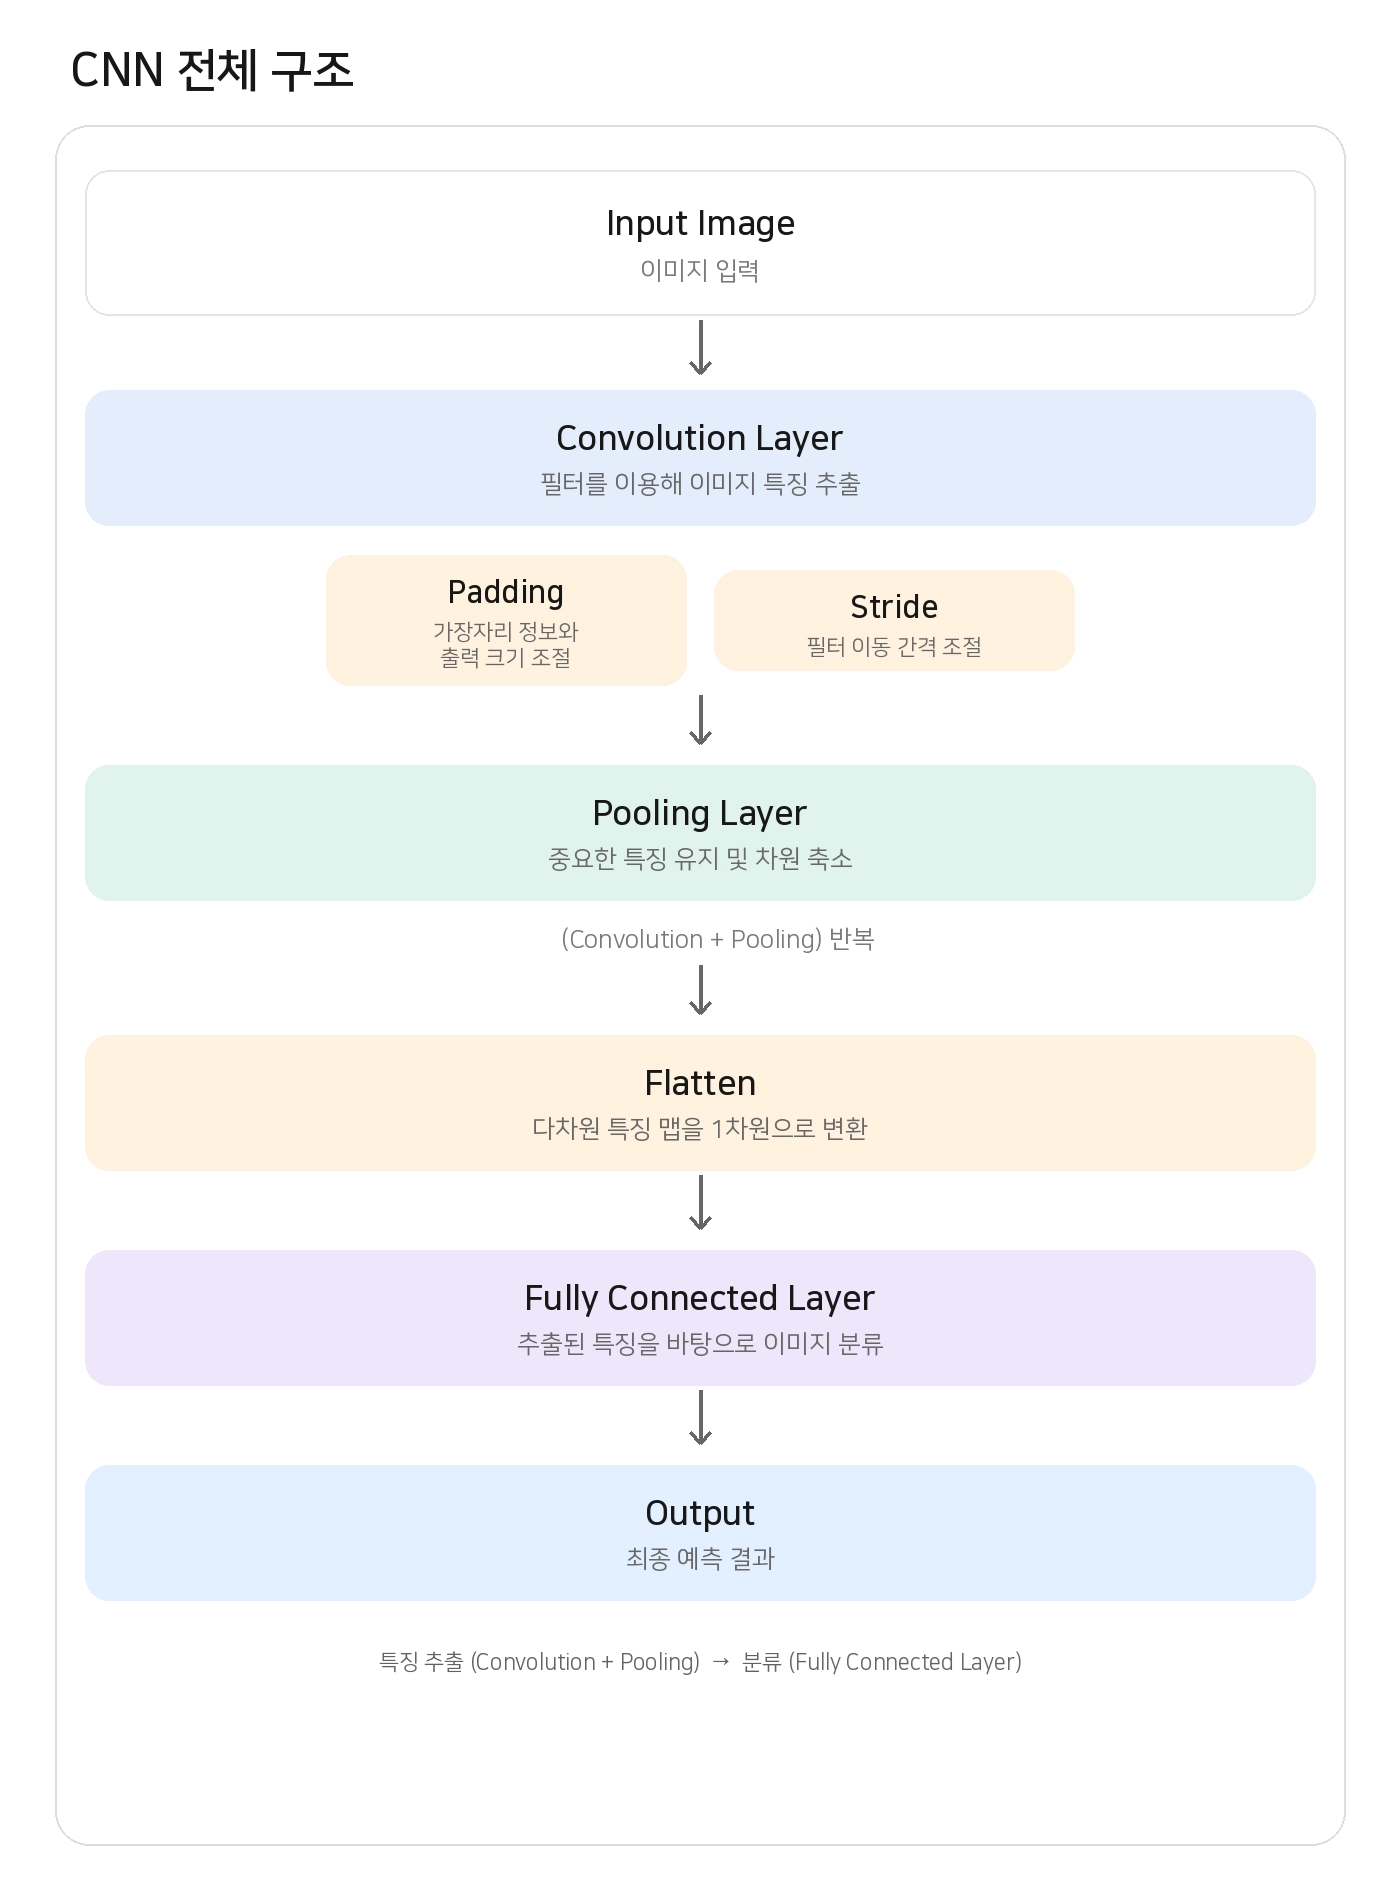

#이미지 딥러닝 응용
##1. **이미지 분류**: 이미지를 픽셀 값으로 인식해서 사전 정의된 클래스 중 하나로 분류

- AlexNet: 비교적 단순한 구조로 초기
CNN모델에서 자주 쓰였으며 작은 데이터셋에 적절
- VGG: 더 깊은 구조로 계산량이 증대해 메모리 요구가 높다
- ResNet: 깊은 네트워크가 가능하지만 과적합을 주의해야 함
- ViT: 이미지를 작은 패치로 나누고 이를 transformer에 입력해 이미지의 특징을 학습하는 모델. attention윽 활용해서 이미지 패치간 관계 학습

> CNN은 이미지 안에 존재하는 여러 객체를 찾아내고 객체의 종류, 위치를 동시에 예측하는데에 활용됨

##2. **객체탐지**: 전체 클래스가 아닌 이미지 안에 있는 개별 객체의 종류와 위치 함께 예측

- **Bounding Box**는 이미지에서 객체의 영역을 둘러싼 사각형
- CNN으로 Feature Map을 얻고 그 위에 두개의 head를 올림
  - 객체의 종류를 예측하는 Classification Head
  - 객체의 위치 좌표를 예측하는 Regression Head

##3. **이미지 캡셔닝**: 이미지의 내용을 자연어 문장으로 표현하는 작업으로 CNN과 RNN 함께 사용

- CNN을 통해 이미지 특징 추출
- RNN을 통해 문장을 생성
  - 문장을 생성하는데 중요한 이미지 영역에 더 높은 가중치를 둬서 단어 생성 (attention)

  









#RNN: 과거를 기억하는 신경망

##순차데이터란?
>데이터의 순서가 의미를 갖는 데이터

1. 정형데이터
  - 순서를 섞어도 의미는 그대로, 샘플 간 관계도 상호 독립적임
2. 순차데이터
  - 순서를 섞으면 의미가 달라지며, 샘플 간 상호 의존적이여서 과거가 현재에 영향을 미침

=> 기존 머신러닝 기법은 순차데이터 처리에는 적절하지 않음. 그래서 나온 모델이 RNN

## RNN 구조
> 기존 신경망과 달리 은닉층에 **순환구조**가 존재

- 순환가중치가 존재함

## 원리
> 현재 입력값 + 이전 은닉상태 -> 새로운 은닉상태를 다음 시점으로 넘김

- 현재 입력 $x_t$ + 이전 은닉 상태 $h_{t-1}$ → 새로운 은닉 상태 $h_t$

$$
h_t = \tanh(Ux_t + Vh_{t-1} + b)
$$

 - 출력
$$
o_t = f(Wh_t + c)
$$

- 이진분류 문제면 활성화 함수는 시그모이드
- 다중 분류 문제면 활성화 함수는 소프트맥스

## RNN 아키텍처
- One to Many: 하나의 입력에서 시퀀스 출력
  - 이비지 캡셔닝 사용
- Many to one: 시퀀스 입력에서 하나의 값 출력
  - 스펨 메일 분류
  - 감정 분류

- Many to Many: 시퀀스 입력에서 시퀀스 출력
  - 객체 태깅 혹은 기계 번역 및 요약

##RNN 한계
1. 시간에 따른 역전파 구조
2. 기울기 소실로 먼 시점의 과거 정보는학습에 거의 반영 x
3. 기울기가 과거 시점으로 갈수록 매우 큰 값이 되는 기울기 폭주로 인해 긴 시퀀스일수록 학습이 불안정
4. 시점을 하나씩 순서대로만 계산할 수 있어서 학습에 시간이 오래걸림

=> 이는 결국 장기의존성 문제, 즉 스퀀스에서 관련된 정보가 멀리 떨어져 있을수록, RNN이 그 관계를 기억하고 학습하지 못함

=> 따라서 중요한 정보는 오래 기억, 불필요한 정부는 잊는 메모리 구조인 **LSTM & GRU** 필요


# LSTM&GRU: 게이트를 통해 중요한 정보는 오래 기억, 불필요한 정보는 버림

## LSTM
>기억을 두 개의 상태로 나눠서 관리해 정보를 더 정교하게 다룰 수 있지만 구조가 복잡하고 계산량이 많음

1) 셀상태 - 장기기억
2) 은닉상태 - 단기기억/출력

-> 기존 RNN은 은닉상태 하나에 모든걸 덮어썼지만, LSTM은 셀상태를 따로 뺴둠

###1. 게이트의 종류
  - 장기기억에서 더이상 불필요한 내용 삭제하는 Forget Gate
  - 새로들어온 정보 중 중요한 것만 장기기억에 저장하는 Input Gate
  - 장기기억 중 지금 필요한 부분만 단기기억으로 내보내는 Output gate


###2. 구조
  - 셀 상태는 정보가 큰 변화 없이 다음 시점으로 흘러감
  - gate가 정보를 구분해서 조절
  - RNN과 달리 순환되는 상태가 은닉상태에 더해 셀상태가 존재
  - RNN과 달리 기억을 갱신할 땐 매 시점 통째로 덮어쓰지 않고 게이트로 선택적으로 지우고 더함

**1. 무엇을 잊을까 계산**
  - 이전 셀 상태의 각 칸에 곱해지는 값에 따라 그대로 유지되거나 잊을지 결정됨

**2. 무엇을 새로 기억할까 계산**
  - 새정보를 얼마나 반영할지, 추가할 후보 정보 결정

**3. 기억 업데이트**
  - 위에서 남긴 기억과 새 정보가 업데이트
  - 덧셈으로 이어짐

**4. 무엇을 내보낼까**
  - 셀의 상태 중 어느부분 내보낼지 결정


###3. 장단점
- 장점
  - 셀 상태의 덧셈구조로 인해 기울기 소실 완화
  - 중요한 정보만 남겨 장기 의존성 학습 가능
  - RNN보다 긴 시퀀스에 강함

- 단점
  - 계산량이 많아 학습이 느리고 메모리 사용이 많음
  - 여전히 시점 순으로 계산

## GRU: 기억을 셀과 은닉상태로 나누지 않고 하나로 통합해서 관리. 위에 LSTM보다 상태 수, 게이트 수 더 가벼움

> LSTM보다 계산이 단순하고 빠르지만 정교함은 상대적으로 떨어짐

- 과거정보: 새정보= n, m으로 정하는 Update Gate
- 과거 기억을 얼마나 무시할건지 정하는 Reset Gate

1. LSTM과의 차이점
- Forget Gate와 Input gate를 update gate 하나로 통합
- Reset gate 사용
- Output gate 없음: 은닉상태 그대로 출력
- Gate 수가 2개로 감소: 덕분에 계산량이 줄고 학습시간이 짧아졌지만 성능도 비슷함

2. 장단점
- 장점
  - 구조가 더 단순해서 쉬움
  - 학습이 빠르고 메모리 사용량 적음
  - 학습도 안정적이고 성능도 LSTM이랑 비슷함
  - Update gate로 기억갱신을 간단히 처리

- 단점
  - 장기 기억과 출력 구분 못함
  - 정교함 떨어짐


# 언제 무엇을 선택? => 정교함과 효율 사이의 선택

- 정교함: LSTM
- 효율: GRU


# Seq2Seq: 입력 시퀀스를 받아 다른 시퀀스를 출력하는 모델

- 입출력의 길이가 달라도 됨
- RNN 아키텍처 중 many to many를 두개의 RNN으로 나눠 구현한 구조
- 읽고(인코더) 요약해서 넘기고 (컨텍스트 벡터) 다시 꺼냄 (디코더)

## Seq2Seq의 구조와 원리
1. 인코더: 입력 문장의 모든 단어를 순서대로 읽고 문장 전체의 정보를 하나의 컨텍스트 벡터로 압축함
    - 단어 토큰화
    - 임베딩
    - LSTM 셀에 한 단어씩 입력
    - 마지막 시점의 은닉상태인 컨텍스트벡터를 디코더로 넘김

2. 디코더: 컨텍스트벡터를 받아 출력 문장을 한 단어씩 순서대로 생성
    - 컨텍스트 벡터를 디코더의 첫 은닉상태로 받음
    - 시작 신호를 첫 입력으로 넣음
    - 매 시점 소프트맥스로 다음 단어 확률 계산해 가장 높은 단어 선택
    - 예측한 단ㄴ어를 다음 시점 입력으로 넣음
    - 종료신호가 나오면 생성 종료

3. 컨텍스트 벡터: 인토더와 디코더 연결 통로
    - 컨텍스트 벡터의 크기는 인코더의 은닉상태 크기로 사람이 정하는 하이퍼파라미터임
    - 차원이 크면 많은 정보를 받지만, 과적합 위험, 계산량 증가
    - 작으면 빠르지만 긴 문장 정보 못담음

##Seq2Seq의 한계: 병목현상
> 인코더가 고정된 크기의 컨텍스트 벡터 하나에 입력문장 전체를 압축해서 정보 손실

